<a href="https://colab.research.google.com/github/Nasim-Amani/tag-recommender-agent-learning/blob/main/CASTRA_summary.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gaps identified in the Related Work

## 2.1 Tag recommendation
- **2.1a No history, no tags:** collaborative filtering needs past behaviour, which new products lack.
- **2.1b Old methods match words, not meaning:** content matching misses synonyms (e.g. "frizzy, damaged hair" ≠ *dry hair*).
- **2.1c Signals used in isolation:** grammar, sentiment, context and similar products are never combined.

## 2.2 Cold-start recommendation
- **Text is assumed clean:** fallback methods rely on product text, but real listings are short, noisy and inconsistent.

## 2.3 Graph neural networks
- **Pairs only:** an edge links two entities, while the signals for a tag form a **group** (product + phrase + sentiment + context).

## 2.4 Hypergraph learning
- **Structure, not content:** hyperedges come from interactions; descriptions and reviews never enter the graph.

## 2.5 Self-supervised learning
- **Language ignored:** self-supervised methods learn only from links and user behaviour, not from product text, which is the most useful clue for tagging.

## 2.6 Sentiment-aware recommendation
- **Sentiment ≠ relevance:** "fast delivery, love it!" says nothing about hair type, yet models count any co-occurring sentiment as support for a tag.

## 2.7 Causal recommendation
- **No causality for tags:** causal methods have been used only to fix biases in *product-to-user* recommendation (e.g. popular items being over-recommended). In tag recommendation, nobody checks whether a clue truly **explains** a tag or just **appears alongside** it (e.g. "smells amazing" often appears on `long lasting` products, but it doesn't make them long lasting).

## Overall gap (2.8)
Each research line solves **one** piece. **No framework combines higher-order structure, language, sentiment, neighbours and causal relevance for tagging**, especially for new products. CASTRA aims to fill this gap.

# How CASTRA addresses each gap

## The big picture: where each gap is handled in the pipeline

    RAW PRODUCT: "Argan Oil Repair Shampoo: restores damaged, frizzy hair" + reviews
            │
            ▼
    ┌──────────────────── STAGE 1: FEATURE EXTRACTION ─────────────────────┐
    │                                                                      │
    │  Semantic (BERT)     -> meaning            ◄── gap 2.1b, 2.2         │
    │  Syntactic (parser)  -> "frizzy hair"      ◄── gap 2.1c, 2.4, 2.5    │
    │  Sentiment           -> hair:+             ◄── gap 2.1c, 2.6         │
    │  Context             -> hair care          ◄── gap 2.1c              │
    │  Neighbors (by text) -> similar shampoos   ◄── gap 2.1a, 2.2         │
    │                                                                      │
    │  Fusion: 4 views -> one product vector z_i (learned layer W_f)       │
    │                                                                      │
    └──────────────────────────────────────────────────────────────────────┘
            │
            ▼
    ┌───────────────────── STAGE 2: HYPERGRAPH + DCHW ─────────────────────┐
    │                                                                      │
    │ A) HYPEREDGE: one per (product, tag) pair, linking 5 node types      │
    │      product   : shampoo                                             │
    │      tag       : dry hair                                            │
    │      phrase    : "frizzy hair"     (from text)                       │
    │      sentiment : hair:+            (from reviews)                    │
    │      context   : hair care                                           │
    │                                                                      │
    │    -> connects 5 nodes at once               ◄── gap 2.3             │
    │    -> text (phrase, sentiment) becomes nodes ◄── gap 2.4             │
    │    -> all signals joined in one hyperedge    ◄── gap 2.1c            │
    │                                                                      │
    │ B) HYPEREDGE WEIGHT w(e) (DCHW)                                      │
    │    1. 5 relevance scores: semantic (meaning), syntactic (grammar),   │
    │       sentiment, neighborhood, causal                                │
    │    2. β = learned importance of each score (sums to 1)               │
    │    3. w(e) = Σ β × score                                             │
    │                                                                      │
    │    -> sentiment is only 1 of 5 scores; its   ◄── gap 2.6             │
    │       importance β is lowered if it doesn't help                     │
    │    -> causal score: does the signal truly    ◄── gap 2.7             │
    │       explain the tag? (never defined!)                              │
    │                                                                      │
    └──────────────────────────────────────────────────────────────────────┘
            │
            ▼
    ┌─────────────────── STAGE 3: HYPERGRAPH NN LAYERS ────────────────────┐
    │                                                                      │
    │ Nodes share information through hyperedges (message passing)         │
    │   each layer: hyperedge averages its nodes × w(e) -> back to nodes   │
    │                                                                      │
    │ hair mask (dry) -> "frizzy hair" -> new shampoo     (2 layers)       │
    │                                                                      │
    │    -> messages come from groups, not pairs   ◄── gap 2.3             │
    │                                                                      │
    └──────────────────────────────────────────────────────────────────────┘
            │
            ▼
    ┌───────── STAGE 4: SELF-SUPERVISED LEARNING (training only) ──────────┐
    │                                                                      │
    │ 2 augmented views of the hypergraph:                                 │
    │   view 1: drop some hyperedges   |   view 2: mask some features      │
    │ Same product in both views -> similar vectors (contrastive loss)     │
    │                                                                      │
    │    -> robust when text/reviews are missing   ◄── gap 2.2             │
    │    -> views built from a text-based graph    ◄── gap 2.5             │
    │                                                                      │
    └──────────────────────────────────────────────────────────────────────┘
            │
            ▼
    ┌───────────── PREDICTION + TRAINING (Sec 3.7, 3.9, 4.3) ──────────────┐
    │                                                                      │
    │ 1) PREDICTION: does this tag fit this product?                       │
    │    input = [product | tag | agree (p×t) | differ (|p-t|)]            │
    │    -> one layer + sigmoid -> probability 0-1                         │
    │    e.g. (new shampoo, dry hair) -> 0.85                              │
    │                                                                      │
    │ 2) TRAINING: learn from TRAIN products' tags only                    │
    │    examples : true tags (answer 1) + random wrong tags (answer 0)    │
    │    loss     : ranking (cross-entropy) + SSL + causal + L2 penalty    │
    │    Optimizer: Adam  |  early stopping on validation NDCG@10          │
    │                                                                      │
    │    -> all stages trained together            ◄── gap 2.8             │
    │                                                                      │
    └──────────────────────────────────────────────────────────────────────┘
            │
            ▼
    ┌──────── STAGE 5: UNCERTAINTY-AWARE RANKING (after training) ─────────┐
    │                                                                      │
    │ MC dropout: predict each (product, tag) many times                   │
    │   mean = relevance  |  SD = uncertainty                              │
    │ Score = mean + causal bonus - SD penalty  -> top-10 tags             │
    │                                                                      │
    │    -> unsure tags are ranked lower           ◄── gap 2.2             │
    │                                                                      │
    └──────────────────────────────────────────────────────────────────────┘

## Gap by gap


| Gap (what existing methods do wrong) | CASTRA's answer | How it works (shampoo example) |
|---|---|---|
| **2.1a** Need purchase history, so new products get no tags | **Neighbors found by text** | On day one, the shampoo's text finds similar products (other repair shampoos); their information enters through the neighbor vector and the neighborhood score $R_{nbr}$. |
| **2.1b** Match words, not meaning | **Semantic encoder (BERT)** | "damaged, frizzy hair" is placed close to `dry hair` by meaning, even with no shared words. |
| **2.1c** Use each signal in isolation | **One hyperedge joins all signals** | The hyperedge {shampoo, `dry hair`, "frizzy hair", `hair:+`, hair care} links product, grammar, sentiment and context together. |
| **2.2** Assume product text is clean and complete | **Many views + SSL + uncertainty** | If the title is short or reviews are missing, other views still help; SSL trains on augmented views with missing parts; unsure tags are ranked lower. |
| **2.3** Graph NNs link only pairs | **Hypergraph** | One hyperedge links 5 nodes at once, instead of 10 separate pairs; message passing then works on whole groups. |
| **2.4** Hypergraphs are built from structure, not text | **Text becomes part of the graph** | Phrases ("frizzy hair") and sentiment (`hair:+`) are **nodes**; text-based relevance scores set the **hyperedge weights**. |
| **2.5** Self-supervised learning ignores text | **SSL on a text-built hypergraph** | The augmented views come from a hypergraph whose nodes and weights are built from text, so the robustness learned covers text signals too. |
| **2.6** Treat any positive or negative review as support for a tag | **Sentiment is only 1 of 5 scores + learned importance $\beta$** | "fast delivery, love it!" adds little, because $\beta$ can lower the importance of sentiment when it doesn't help. |
| **2.7** Can't tell whether a clue explains a tag or just appears with it | **Causal relevance score $R_{causal}$** | A learned scorer judges whether "so soft" really supports `dry hair`; it both weights each hyperedge and adds a bonus to the final tag score. |
| **2.8** No single framework combines all of these | **One end-to-end model** | All stages are trained together with one combined loss. |

# Experiments and results (Sec 5–6)

## 1. What they tested

| Item | In the paper |
|---|---|
| **Research questions** | RQ1 beat traditional methods? · RQ2 work on different datasets? · RQ3 consistent across metrics? · RQ4 do causal + SSL help? |
| **Datasets** | **MovieLens** (movies, structured) · **Last.fm** (music + tags, sparser) |
| **Baselines** | Random · Popularity · TF-IDF · BM25 · SVD-LogReg (all classic) |
| **Metrics @10** | **Finding:** Precision, Recall, HitRate · **Ranking:** NDCG, MAP, MRR |
| **Setup** | top-10 recommendations, Adam, 500 epochs, one random seed (42) |

## 2. What came out (Table 4)

| Dataset | CASTRA wins | Best on the other metrics |
|---|---|---|
| **MovieLens** | **Ranking**: NDCG, MAP, MRR | **Popularity** wins finding (P, R, HR) |
| **Last.fm** | **Finding**: P, R, HR | **SVD-LogReg** wins ranking (NDCG, MAP, MRR) |

**Overall summaries (Sec 5.8–5.10):**

| Summary | CASTRA | Next best |
|---|---|---|
| Wins (out of 12) | **6** | Popularity 3, SVD-LogReg 3 |
| Average rank (lower = better) | **1.50** | Popularity 2.00 |
| Relative performance (1 = always best) | **0.960** | Popularity 0.922 |

## 3. How the authors explain it (Sec 6)
- **6.1:** CASTRA is the most **balanced** method: never far from the best.
- **6.2:** the **causal** part explains the better **ranking** (MovieLens).
- **6.3:** **SSL** explains the better **finding** on sparse data (Last.fm).
- **6.4:** classic methods lose because word matching and popularity can't capture complex relations.
- **6.5:** training is **stable**: all four losses decrease smoothly.

## 4. Their conclusion (Sec 7)
CASTRA is **competitive across datasets and metrics**, and combining causal + self-supervised learning brings **complementary benefits**.

# Questions
## A. experiments

1. **Cold-start and promised metrics:** the abstract mentions cold-start robustness and the metrics Cold-Start Gain, Coverage and Diversity, but these are not reported in the experiments.
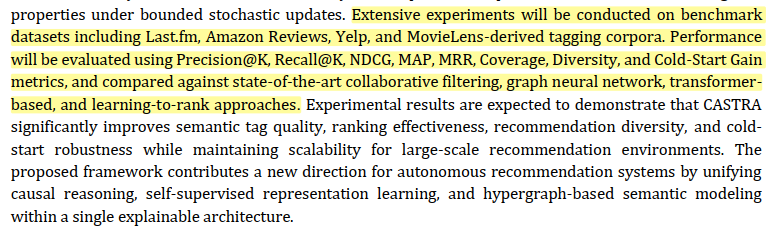



2. **Ablation:** can we remove each part (DCHW, SSL, causal, syntax, sentiment, uncertainty) to show what each contributes? for answering to RQ4.

3. **Popularity:** Popularity recommends the same most common tags to every product without learning anything, yet it beats CASTRA on 3 MovieLens metrics. Are the test answers dominated by a few common tags?
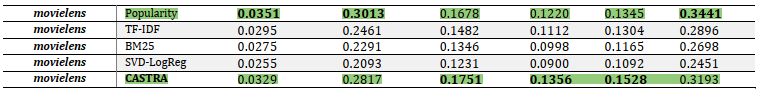

## B. Method details that are undefined


4. **Tag vectors** $z_{t_j}$: how are they created?
(They are used in several steps: the relevance scores $R_{sem}$, $R_{sent}$ and $R_{causal}$ and the importance weights $\beta$ (Sec 3.4), as the starting features of tag nodes in the hypergraph layers (Sec 3.5), and in the prediction head (Sec 3.7).)

5. **Context** $c_i$: is it the product category, or something else (e.g. brand, price range)? (The paper calls it "contextual information" ($s_i$ in Sec 3.2, $c_i$ later) and uses it as a hypergraph node and in $R_{causal}$, but never says where it comes from or how the Context Encoder (Figure 1) works.)

6. **Unused inputs:** **attributes** $a_i$ (Sec 3.2, e.g. brand, material) and **"Existing Tags"** (Figure 1) are listed as inputs but never appear in any formula. Which step uses them? (Similarly, if the optional "User Interactions" are provided, where would they enter?)

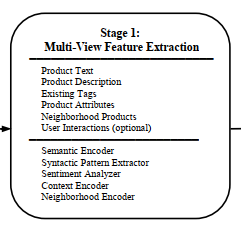

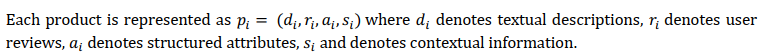

7. **Syntactic part: Encoder** $f_{syn}$ (Sec 3.3): it turns each product's dependency graph into a vector $z^{syn}_i$, but no architecture is given. Is it a graph neural network, or something simpler?

8. **Sentiment part** (Sec 3.3–3.4): the paper says reviews are turned into a sentiment vector that captures polarity, subjectivity and aspect sentiment, but it doesn't explain how.


9. **Neighbors** (Sec 3.3): the paper says each product borrows information from similar products, weighted by how similar they are, but it doesn't explain how.


10. **Figure vs text:** Figure 1 shows 3 node types and 5 hyperedge types; Sec 3.4 has 5 node types and 1 hyperedge type. Which is correct?


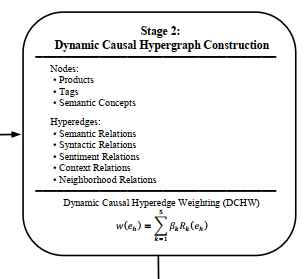

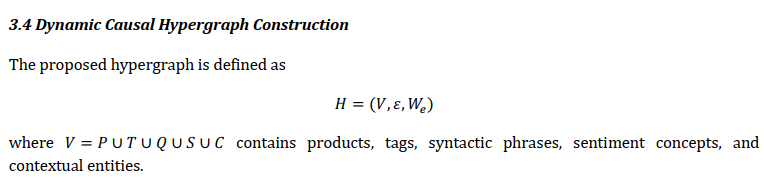

11. **Users:** the conclusion (Sec 7.1) and Sec 6.3 say CASTRA models relationships among users, items and tags, but the hypergraph (Sec 3.4) has no user nodes. Are users part of the model, or should this wording be corrected?


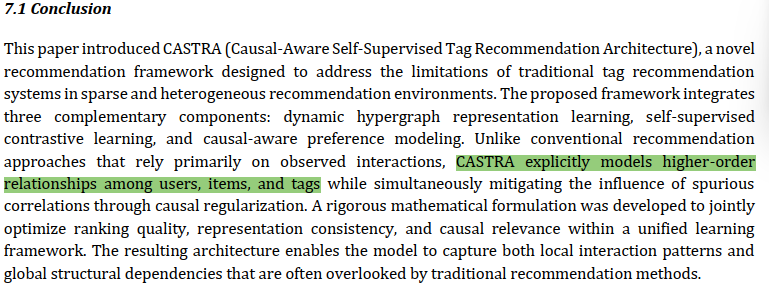

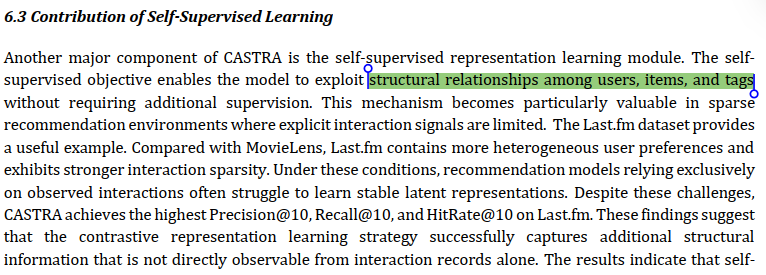

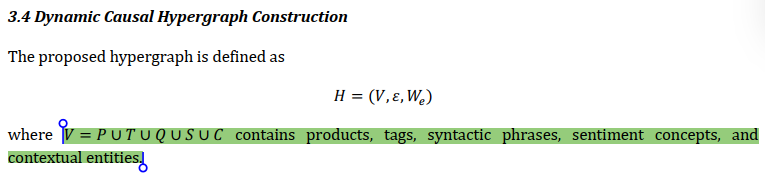



12. **Explainability:** the paper calls CASTRA  "explainable" but there is no explanation part.



## C. Reproducibility
13. **Table 1 (datasets):** the table shows only the seed and K. Can I know:
   - **Size:** number of products, tags and interactions
   - **Sparsity:** how much of the product–tag table is empty
   - **Split strategy:** how train/validation/test were made (random, by time, or new products held out)

14. **Training curves:** Sec 6.5 refers to curves "in Section 5" but it is not there.

## D. More
15. **"Autonomous":** the method is not agentic.is it still Autonomous?
